# microgpt walkthrough: a complete GPT in 200 lines

Computational Physics II (PHY4008) · Original code: Andrej Karpathy, [`microgpt.py`](https://gist.github.com/karpathy/8627fe009c40f57531cb18360106ce95) (2026)

> "This file is the complete algorithm. Everything else is just efficiency."

**How to read this notebook**

- The code cells are the original `microgpt.py`, cut in order from top to bottom. Not a character is changed.
- Only cells and lines marked `# [added]` were added for this lecture (checks and plots).
- Run the cells from top to bottom. No external library is needed, except `matplotlib` for the plot cells.
- The training cell in §6 is pure Python and takes 1 to 2 minutes.

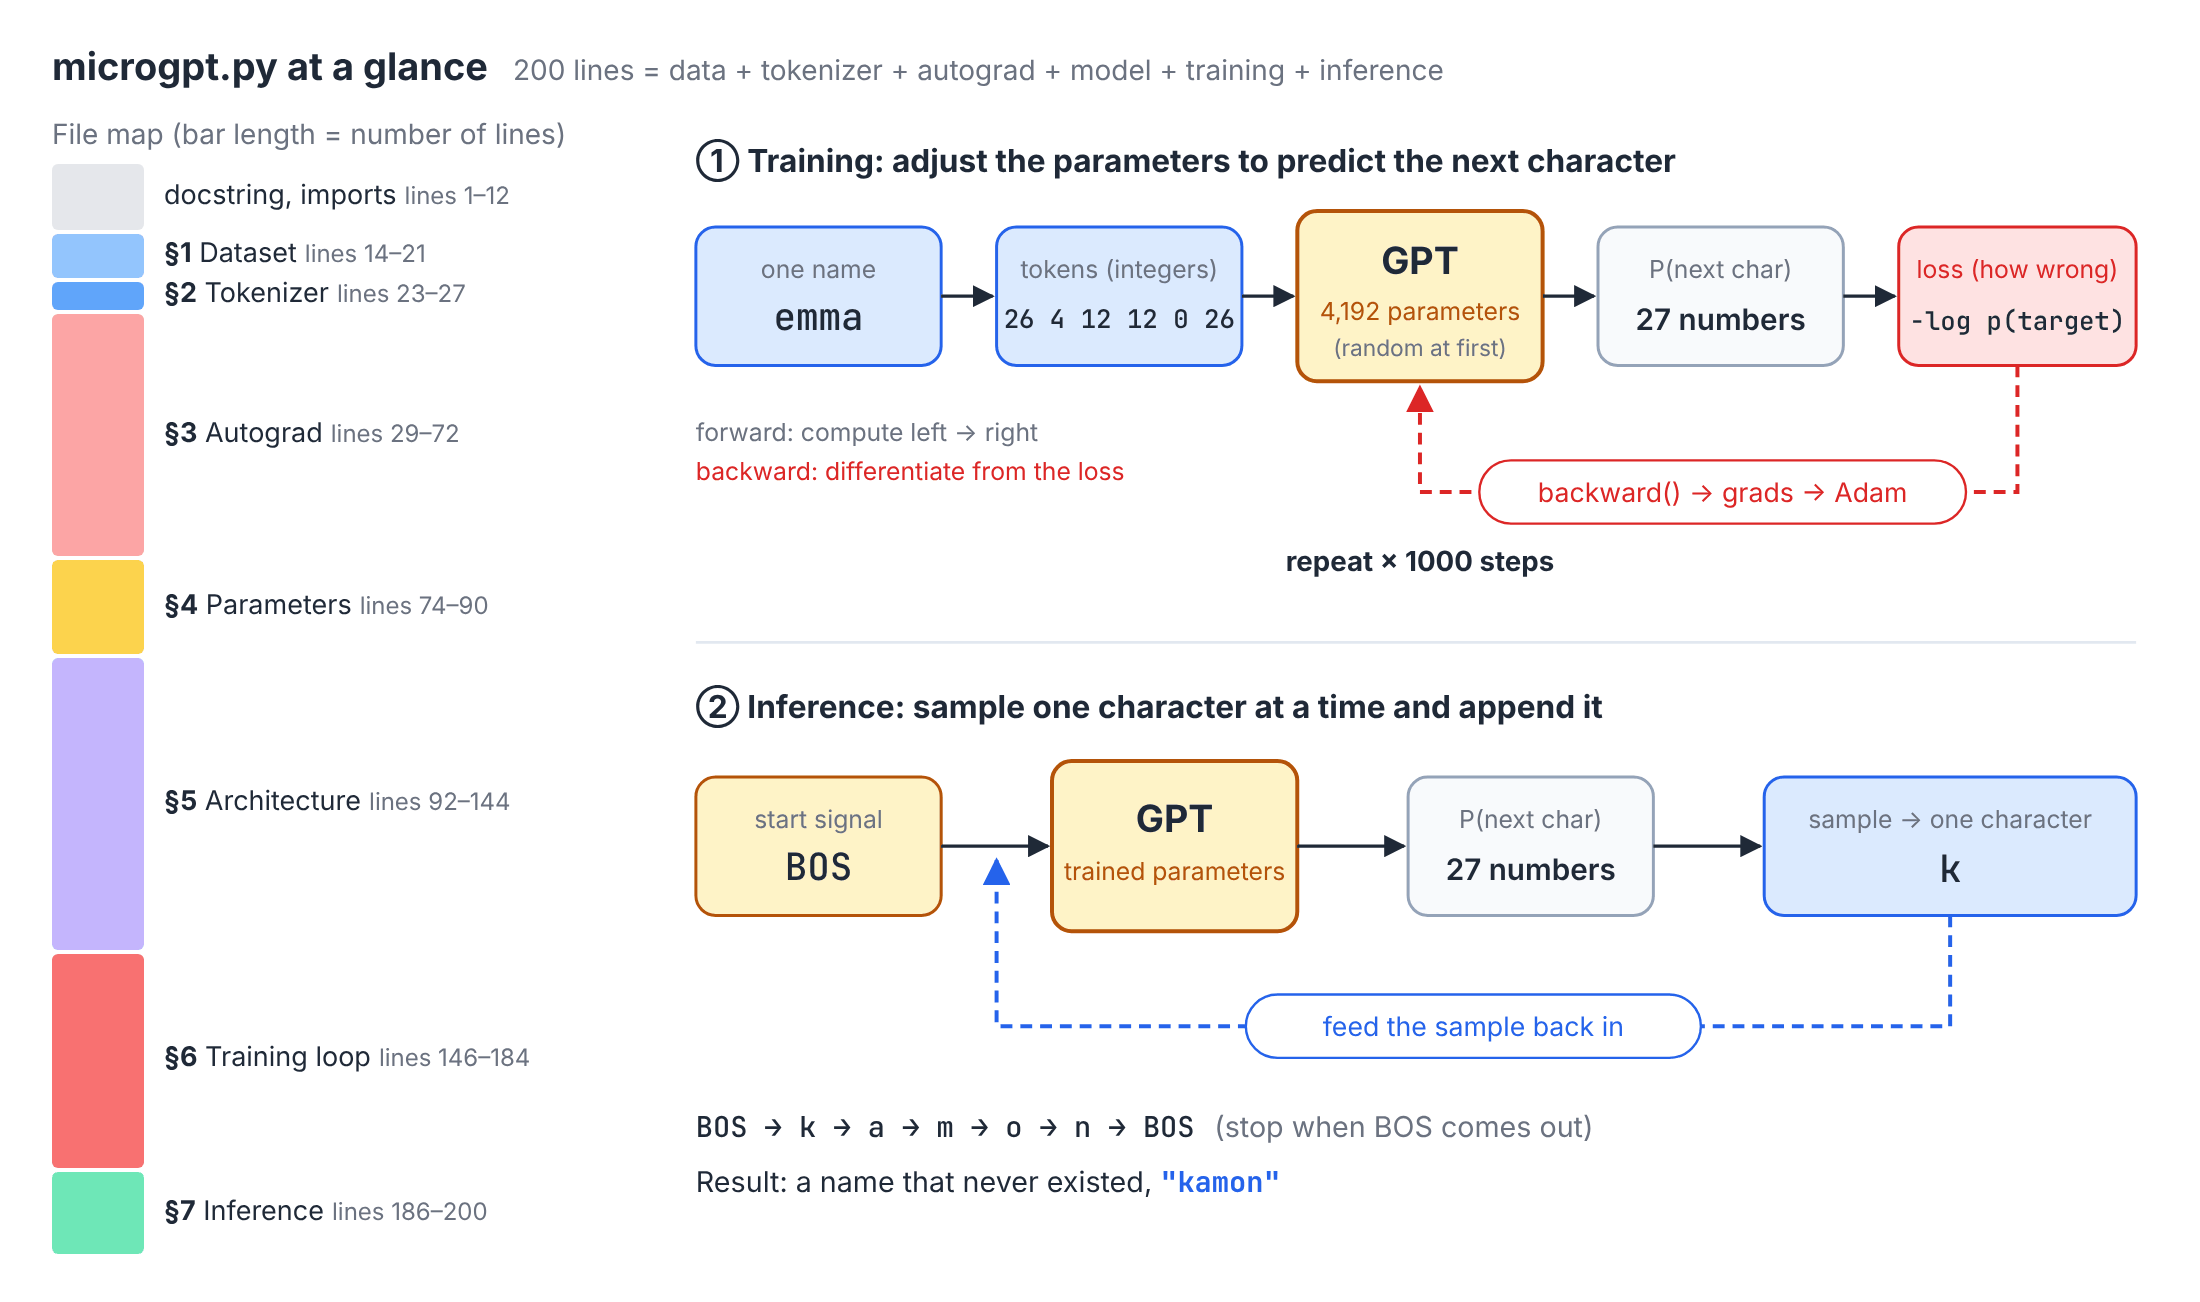

| Section | Content | Original lines | Summary |
|---|---|---|---|
| §1 | Dataset | 14–21 | 32,000 names |
| §2 | Tokenizer | 23–27 | characters ↔ integers |
| §3 | Autograd | 29–72 | automatic derivatives (chain rule) |
| §4 | Parameters | 74–90 | 4,192 random numbers |
| §5 | Architecture | 92–144 | token → next-character scores |
| §6 | Training loop | 146–184 | update the parameters × 1000 |
| §7 | Inference | 186–200 | generate new names |

## §0 Setup <small>(lines 1–12)</small>

Only three modules are used: `os`, `math`, `random`. The random seed is fixed, so every run gives the same result.

In [1]:
"""
The most atomic way to train and run inference for a GPT in pure, dependency-free Python.
This file is the complete algorithm.
Everything else is just efficiency.

@karpathy
"""

import os       # os.path.exists
import math     # math.log, math.exp
import random   # random.seed, random.choices, random.gauss, random.shuffle
random.seed(42) # Let there be order among chaos

## §1 Dataset <small>(lines 14–21)</small>

- One document = one name. `docs` is a list of name strings.
- `input.txt` is downloaded if it is missing. **To use other data, replace `input.txt`** (one item per line).
- Goal: learn the statistical patterns of these names and generate similar names that do not exist.

In [2]:
# Let there be a Dataset `docs`: list[str] of documents (e.g. a list of names)
if not os.path.exists('input.txt'):
    import urllib.request
    names_url = 'https://raw.githubusercontent.com/karpathy/makemore/988aa59/names.txt'
    urllib.request.urlretrieve(names_url, 'input.txt')
docs = [line.strip() for line in open('input.txt') if line.strip()]
random.shuffle(docs)
print(f"num docs: {len(docs)}")

num docs: 32033


In [3]:
# [added] look at the data
print(docs[:8])
print("longest name:", max(docs, key=len), "/ mean length:", round(sum(len(d) for d in docs) / len(docs), 1))

['yuheng', 'diondre', 'xavien', 'jori', 'juanluis', 'erandi', 'phia', 'samatha']
longest name: muhammadmustafa / mean length: 6.1


## §2 Tokenizer <small>(lines 23–27)</small>

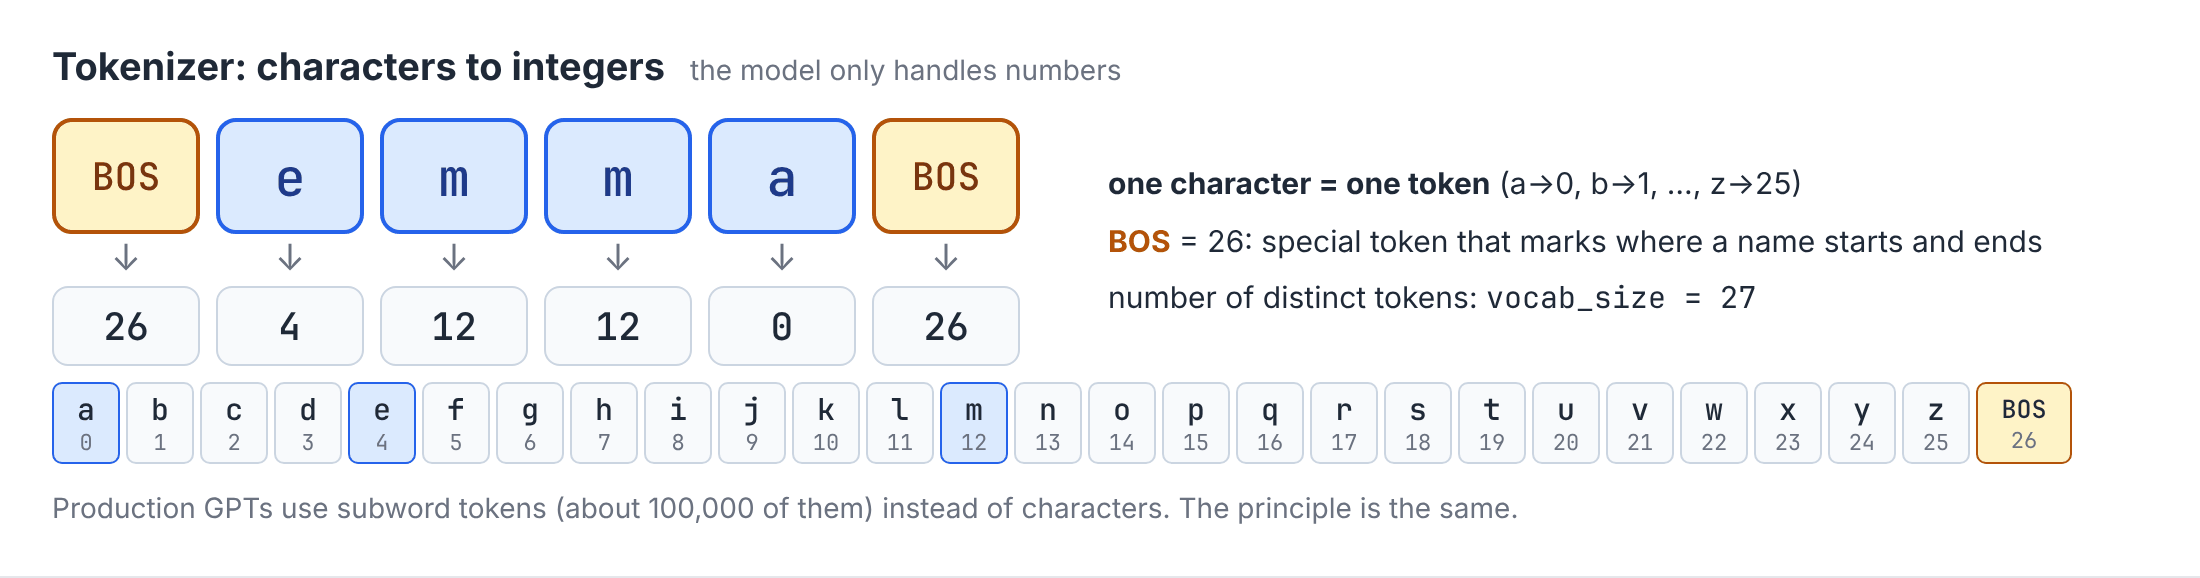

In [4]:
# Let there be a Tokenizer to translate strings to sequences of integers ("tokens") and back
uchars = sorted(set(''.join(docs))) # unique characters in the dataset become token ids 0..n-1
BOS = len(uchars) # token id for a special Beginning of Sequence (BOS) token
vocab_size = len(uchars) + 1 # total number of unique tokens, +1 is for BOS
print(f"vocab size: {vocab_size}")

vocab size: 27


In [5]:
# [added] "emma" as tokens (same expression as line 157 of the training loop)
doc = "emma"
tokens = [BOS] + [uchars.index(ch) for ch in doc] + [BOS]
print(tokens)
print([uchars[t] if t != BOS else "BOS" for t in tokens])   # back again: integers -> characters

[26, 4, 12, 12, 0, 26]
['BOS', 'e', 'm', 'm', 'a', 'BOS']


## §3 Autograd <small>(lines 29–72)</small>

Training needs the **derivative of the loss** with respect to all 4,192 parameters: if a parameter increases slightly, how much does the loss change?
The derivatives are not derived by hand. Each operation is recorded in a graph, and the chain rule is applied by walking the graph backwards.

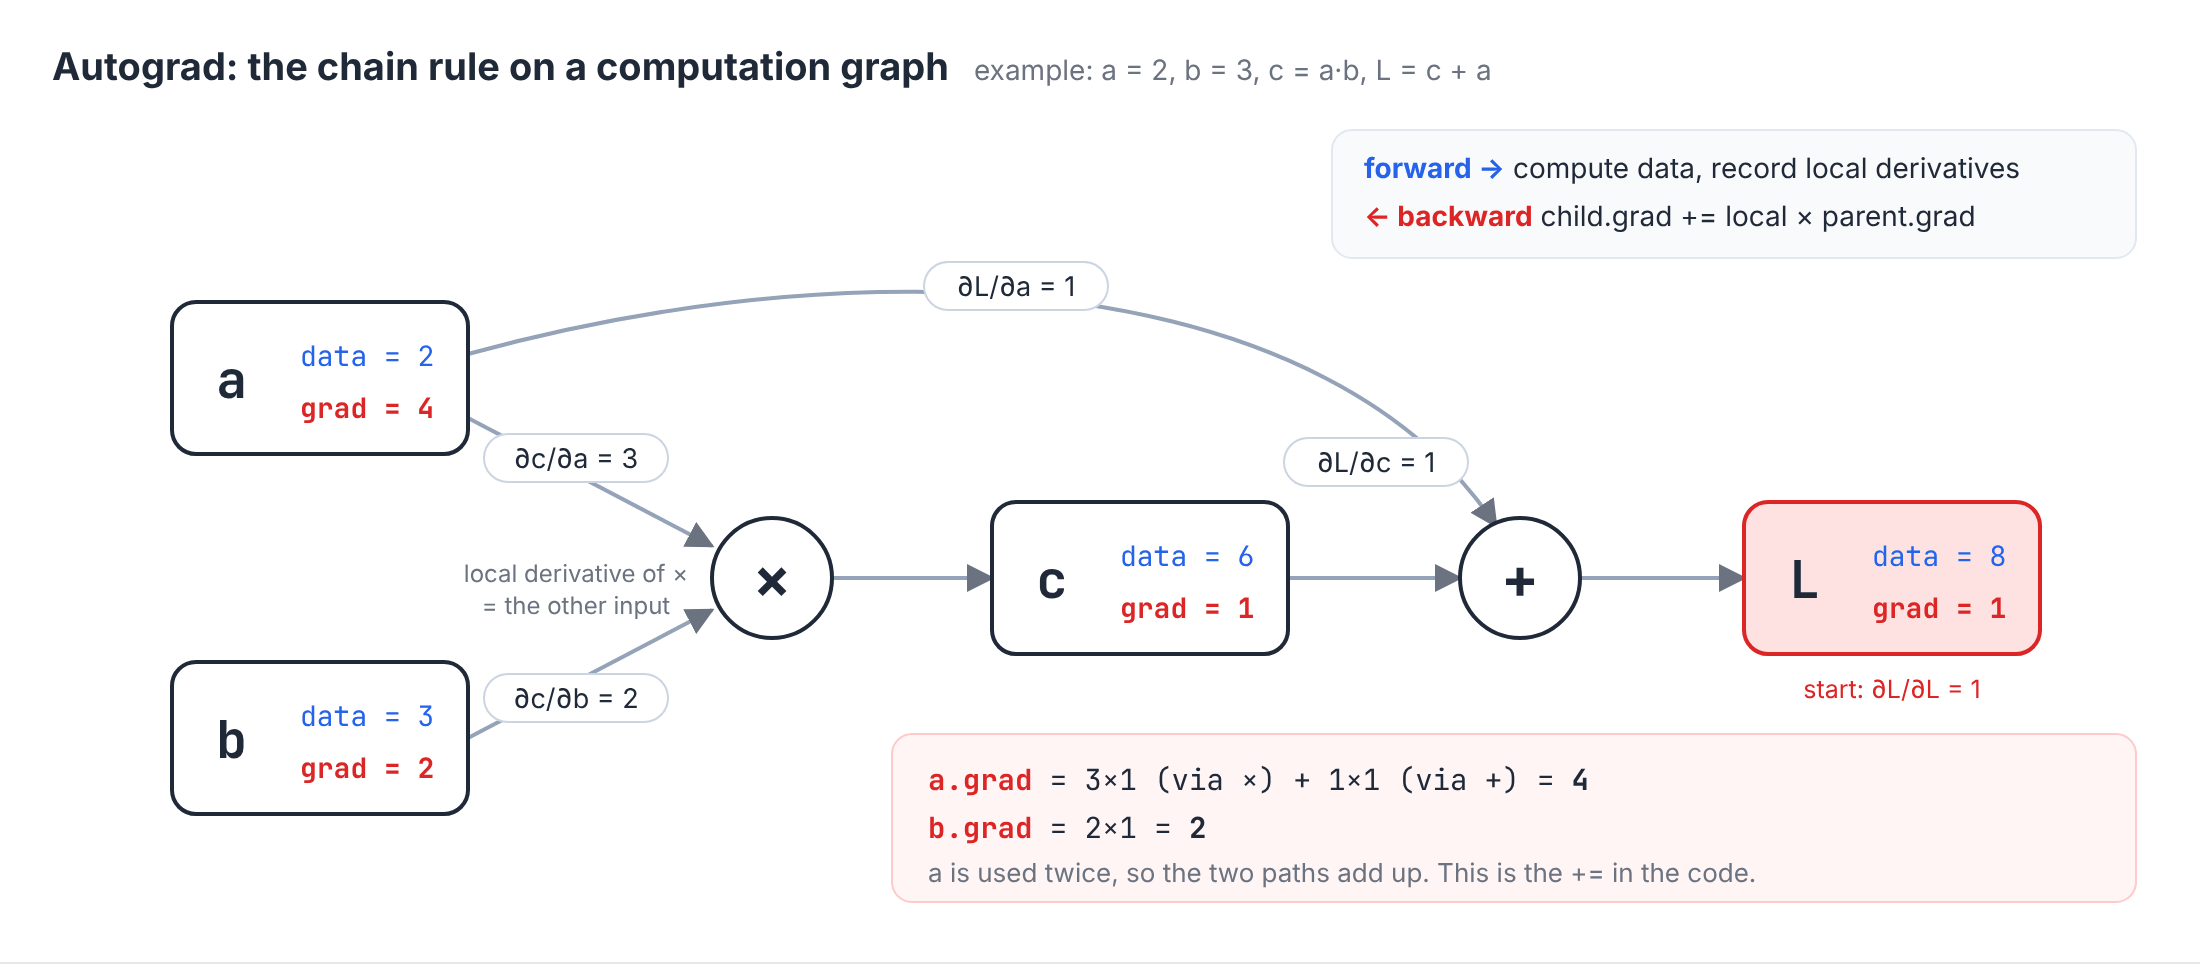

One `Value` = one number + a record of how it was computed.

| Operation | Forward | Local derivatives (`_local_grads`) |
|---|---|---|
| `a + b` | $a+b$ | $1,\ 1$ |
| `a * b` | $ab$ | $b,\ a$ |
| `a ** n` | $a^n$ | $n a^{n-1}$ |
| `a.log()` | $\ln a$ | $1/a$ |
| `a.exp()` | $e^a$ | $e^a$ |
| `a.relu()` | $\max(0,a)$ | 1 if $a>0$, else 0 |

- **Lines 39–57**: every operation creates a new `Value` and stores its children and local derivatives (forward).
- **Lines 59–72**, `backward()`: sort the graph topologically, then go from the output to the inputs with `child.grad += local_grad * v.grad`.

In [6]:
# Let there be Autograd to recursively apply the chain rule through a computation graph
class Value:
    __slots__ = ('data', 'grad', '_children', '_local_grads') # Python optimization for memory usage

    def __init__(self, data, children=(), local_grads=()):
        self.data = data                # scalar value of this node calculated during forward pass
        self.grad = 0                   # derivative of the loss w.r.t. this node, calculated in backward pass
        self._children = children       # children of this node in the computation graph
        self._local_grads = local_grads # local derivative of this node w.r.t. its children

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        return Value(self.data + other.data, (self, other), (1, 1))

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        return Value(self.data * other.data, (self, other), (other.data, self.data))

    def __pow__(self, other): return Value(self.data**other, (self,), (other * self.data**(other-1),))
    def log(self): return Value(math.log(self.data), (self,), (1/self.data,))
    def exp(self): return Value(math.exp(self.data), (self,), (math.exp(self.data),))
    def relu(self): return Value(max(0, self.data), (self,), (float(self.data > 0),))
    def __neg__(self): return self * -1
    def __radd__(self, other): return self + other
    def __sub__(self, other): return self + (-other)
    def __rsub__(self, other): return other + (-self)
    def __rmul__(self, other): return self * other
    def __truediv__(self, other): return self * other**-1
    def __rtruediv__(self, other): return other * self**-1

    def backward(self):
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._children:
                    build_topo(child)
                topo.append(v)
        build_topo(self)
        self.grad = 1
        for v in reversed(topo):
            for child, local_grad in zip(v._children, v._local_grads):
                child.grad += local_grad * v.grad

In [7]:
# [added] the example in the figure (from Karpathy's blog post)
a = Value(2.0)
b = Value(3.0)
c = a * b       # 6
L = c + a       # 8
L.backward()
print(a.grad, b.grad)   # dL/da = b + 1 = 4,  dL/db = a = 2

4.0 2.0


**Check against numerical differentiation.** Take an arbitrary function and compare with the central difference $\dfrac{f(x+h)-f(x-h)}{2h}$.

In [8]:
# [added] autograd vs numerical derivative
def f(x, y):
    return (x * y + y.exp()).log() / x + (x - y).relu() ** 2

x, y = Value(1.5), Value(0.7)
f(x, y).backward()

h = 1e-5
num_dx = (f(Value(1.5 + h), Value(0.7)).data - f(Value(1.5 - h), Value(0.7)).data) / (2 * h)
num_dy = (f(Value(1.5), Value(0.7 + h)).data - f(Value(1.5), Value(0.7 - h)).data) / (2 * h)
print(f"autograd  : df/dx = {x.grad:.6f}   df/dy = {y.grad:.6f}")
print(f"numerical : df/dx = {num_dx:.6f}   df/dy = {num_dy:.6f}")

autograd  : df/dx = 1.254701   df/dy = -0.835414
numerical : df/dx = 1.254701   df/dy = -0.835414


Numerical differentiation needs two function evaluations per parameter (8,384 evaluations for 4,192 parameters).
Autograd gets all of them from **one backward pass**. This is what `loss.backward()` does in PyTorch; the only difference is that PyTorch works on tensors instead of scalars.

## §4 Parameters <small>(lines 74–90)</small>

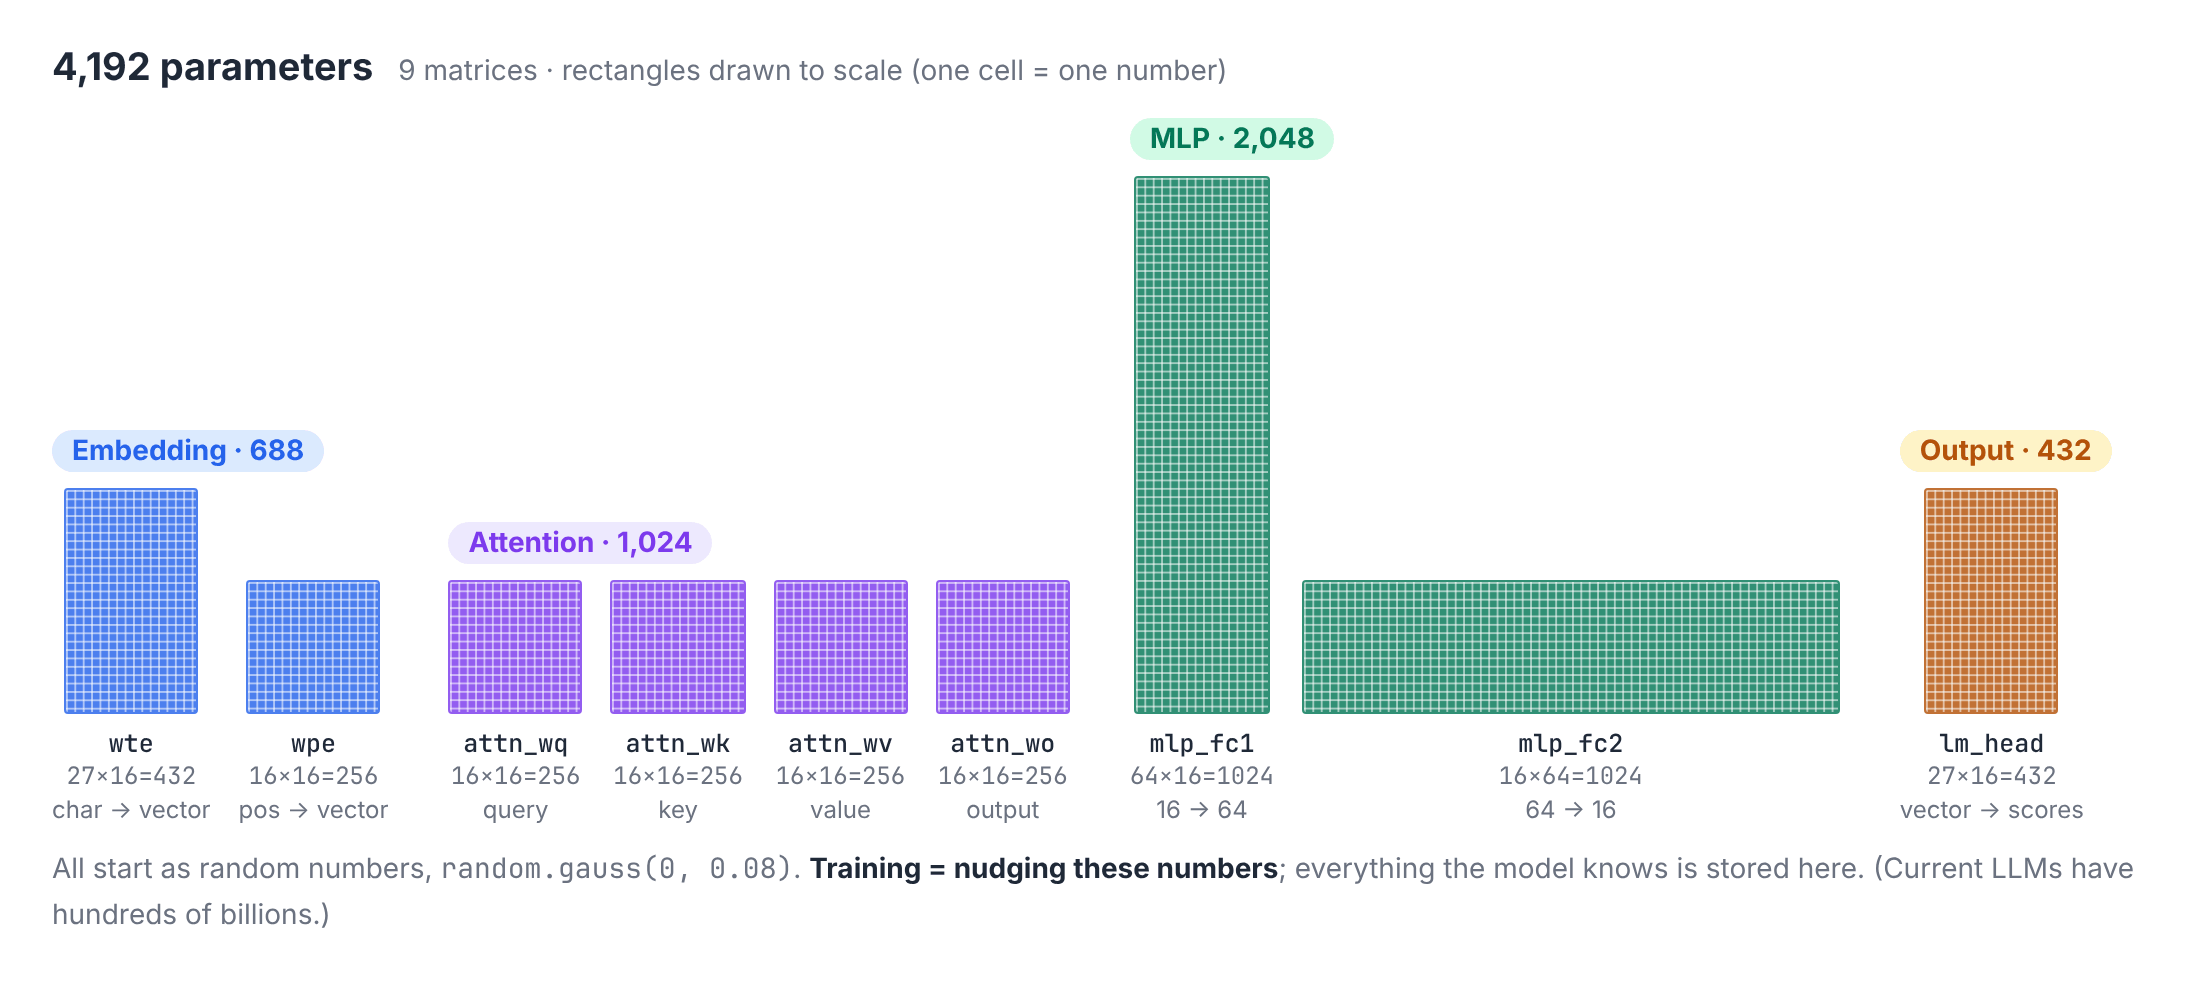

- `matrix(nout, nin)`: an `nout × nin` matrix of random numbers (a list of lists of `Value`).
- `state_dict`: name → matrix. `params`: all of them flattened into one list (the optimizer loops over it).
- Numbers that set the size: `n_embd = 16` (vector dimension), `n_head = 4`, `n_layer = 1`, `block_size = 16` (maximum length).

In [9]:
# Initialize the parameters, to store the knowledge of the model
n_layer = 1     # depth of the transformer neural network (number of layers)
n_embd = 16     # width of the network (embedding dimension)
block_size = 16 # maximum context length of the attention window (note: the longest name is 15 characters)
n_head = 4      # number of attention heads
head_dim = n_embd // n_head # derived dimension of each head
matrix = lambda nout, nin, std=0.08: [[Value(random.gauss(0, std)) for _ in range(nin)] for _ in range(nout)]
state_dict = {'wte': matrix(vocab_size, n_embd), 'wpe': matrix(block_size, n_embd), 'lm_head': matrix(vocab_size, n_embd)}
for i in range(n_layer):
    state_dict[f'layer{i}.attn_wq'] = matrix(n_embd, n_embd)
    state_dict[f'layer{i}.attn_wk'] = matrix(n_embd, n_embd)
    state_dict[f'layer{i}.attn_wv'] = matrix(n_embd, n_embd)
    state_dict[f'layer{i}.attn_wo'] = matrix(n_embd, n_embd)
    state_dict[f'layer{i}.mlp_fc1'] = matrix(4 * n_embd, n_embd)
    state_dict[f'layer{i}.mlp_fc2'] = matrix(n_embd, 4 * n_embd)
params = [p for mat in state_dict.values() for row in mat for p in row] # flatten params into a single list[Value]
print(f"num params: {len(params)}")

num params: 4192


In [10]:
# [added] shape of each matrix
for name, mat in state_dict.items():
    print(f"{name:16s} {len(mat):3d} x {len(mat[0]):2d} = {len(mat) * len(mat[0]):5d}")

wte               27 x 16 =   432
wpe               16 x 16 =   256
lm_head           27 x 16 =   432
layer0.attn_wq    16 x 16 =   256
layer0.attn_wk    16 x 16 =   256
layer0.attn_wv    16 x 16 =   256
layer0.attn_wo    16 x 16 =   256
layer0.mlp_fc1    64 x 16 =  1024
layer0.mlp_fc2    16 x 64 =  1024


## §5 Architecture <small>(lines 92–144)</small>

### 5.1 Three building blocks <small>(lines 92–106)</small>

| Function | What it does | Intuition |
|---|---|---|
| `linear(x, w)` | matrix × vector | a learnable map from one vector to another |
| `softmax(logits)` | scores → probabilities | Boltzmann distribution (figure below) |
| `rmsnorm(x)` | rescales a vector to unit rms | keeps values from growing or vanishing through the layers |

In [11]:
# Define the model architecture: a function mapping tokens and parameters to logits over what comes next
# Follow GPT-2, blessed among the GPTs, with minor differences: layernorm -> rmsnorm, no biases, GeLU -> ReLU
def linear(x, w):
    return [sum(wi * xi for wi, xi in zip(wo, x)) for wo in w]

def softmax(logits):
    max_val = max(val.data for val in logits)
    exps = [(val - max_val).exp() for val in logits]
    total = sum(exps)
    return [e / total for e in exps]

def rmsnorm(x):
    ms = sum(xi * xi for xi in x) / len(x)
    scale = (ms + 1e-5) ** -0.5
    return [xi * scale for xi in x]

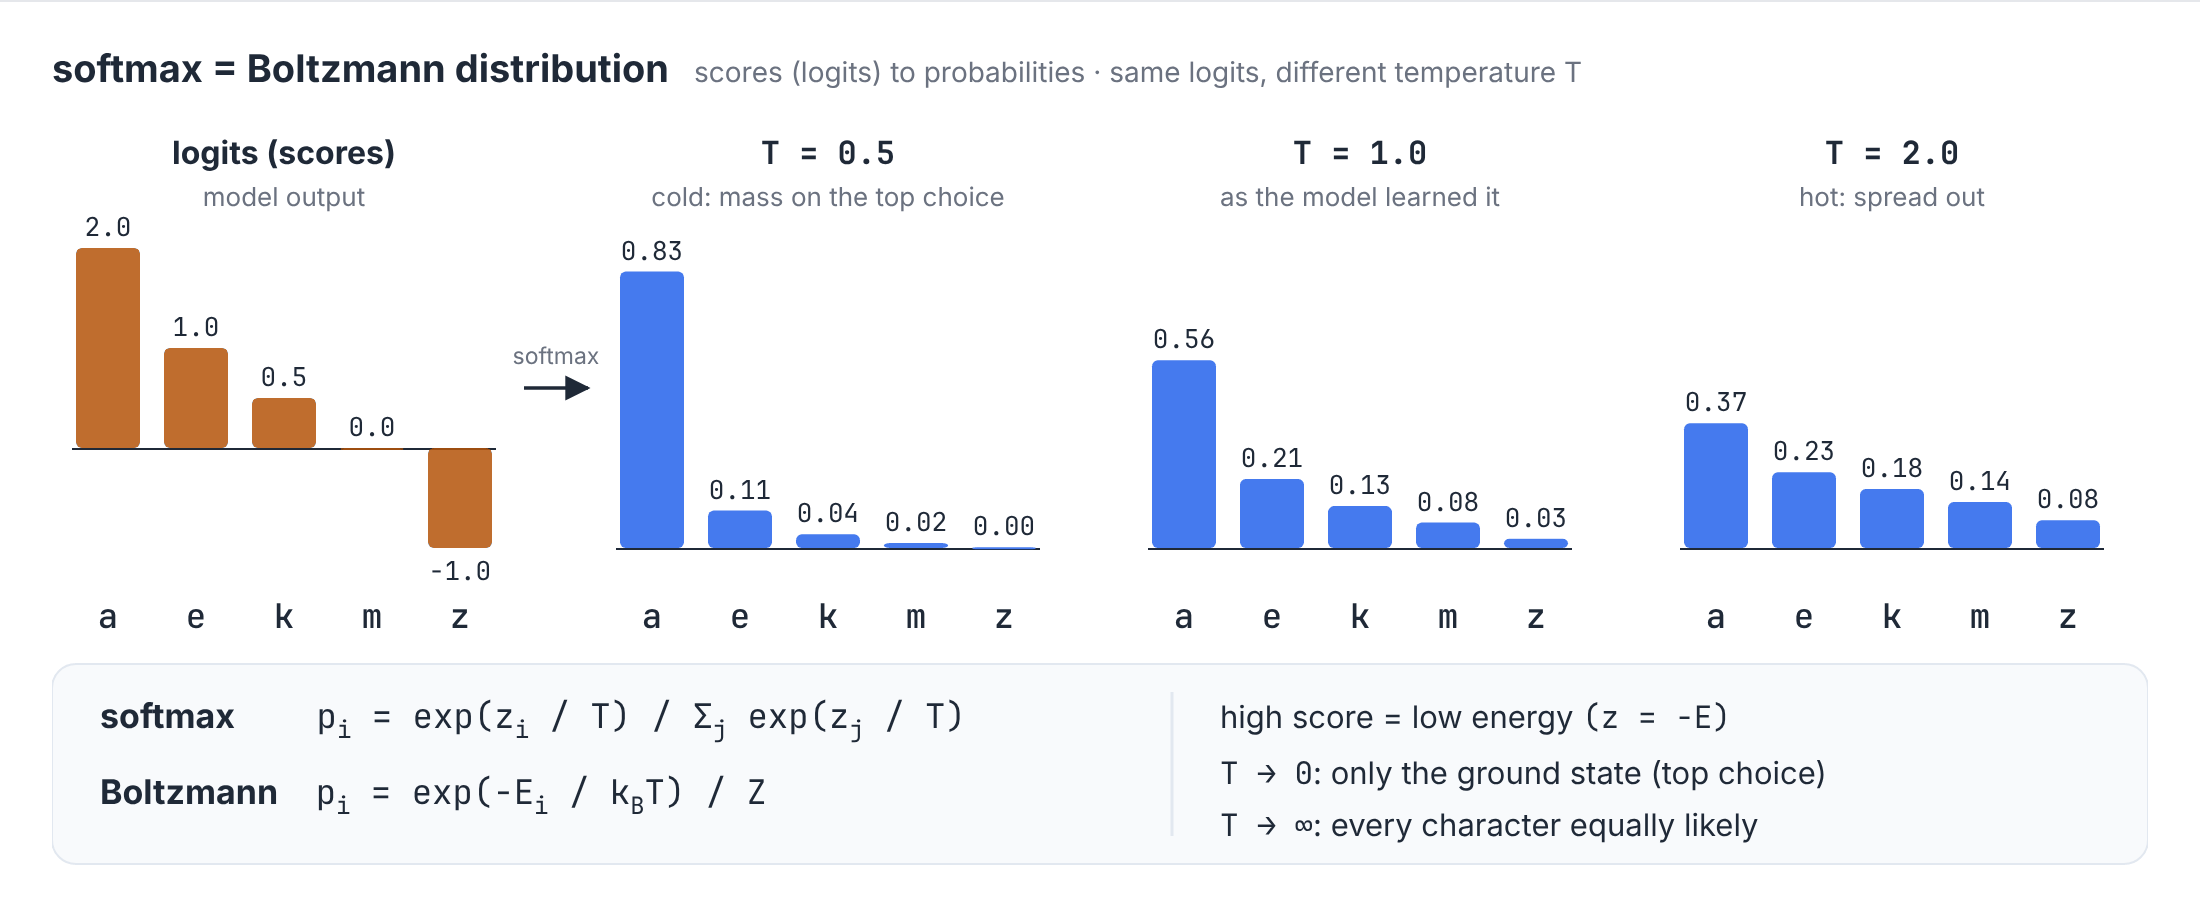

In [12]:
# [added] softmax with a temperature: divide the logits by T (same as line 195 of the inference code)
logits = [Value(2.0), Value(1.0), Value(0.5), Value(0.0), Value(-1.0)]
for T in [0.5, 1.0, 2.0]:
    probs = softmax([l / T for l in logits])
    print(f"T = {T}:", "  ".join(f"{p.data:.2f}" for p in probs))

# [added] rmsnorm: same direction, rms rescaled to 1
print("rmsnorm([3, 4]) =", [round(xi.data, 3) for xi in rmsnorm([Value(3.0), Value(4.0)])])

T = 0.5: 0.83  0.11  0.04  0.02  0.00
T = 1.0: 0.56  0.21  0.13  0.08  0.03
T = 2.0: 0.37  0.23  0.18  0.14  0.08
rmsnorm([3, 4]) = [0.849, 1.131]


### 5.2 The model `gpt()` <small>(lines 108–144)</small>

Input: one token (`token_id`), its position (`pos_id`), and the `keys` and `values` left by earlier positions.
Output: one score (`logit`) for each of the 27 possible next characters.

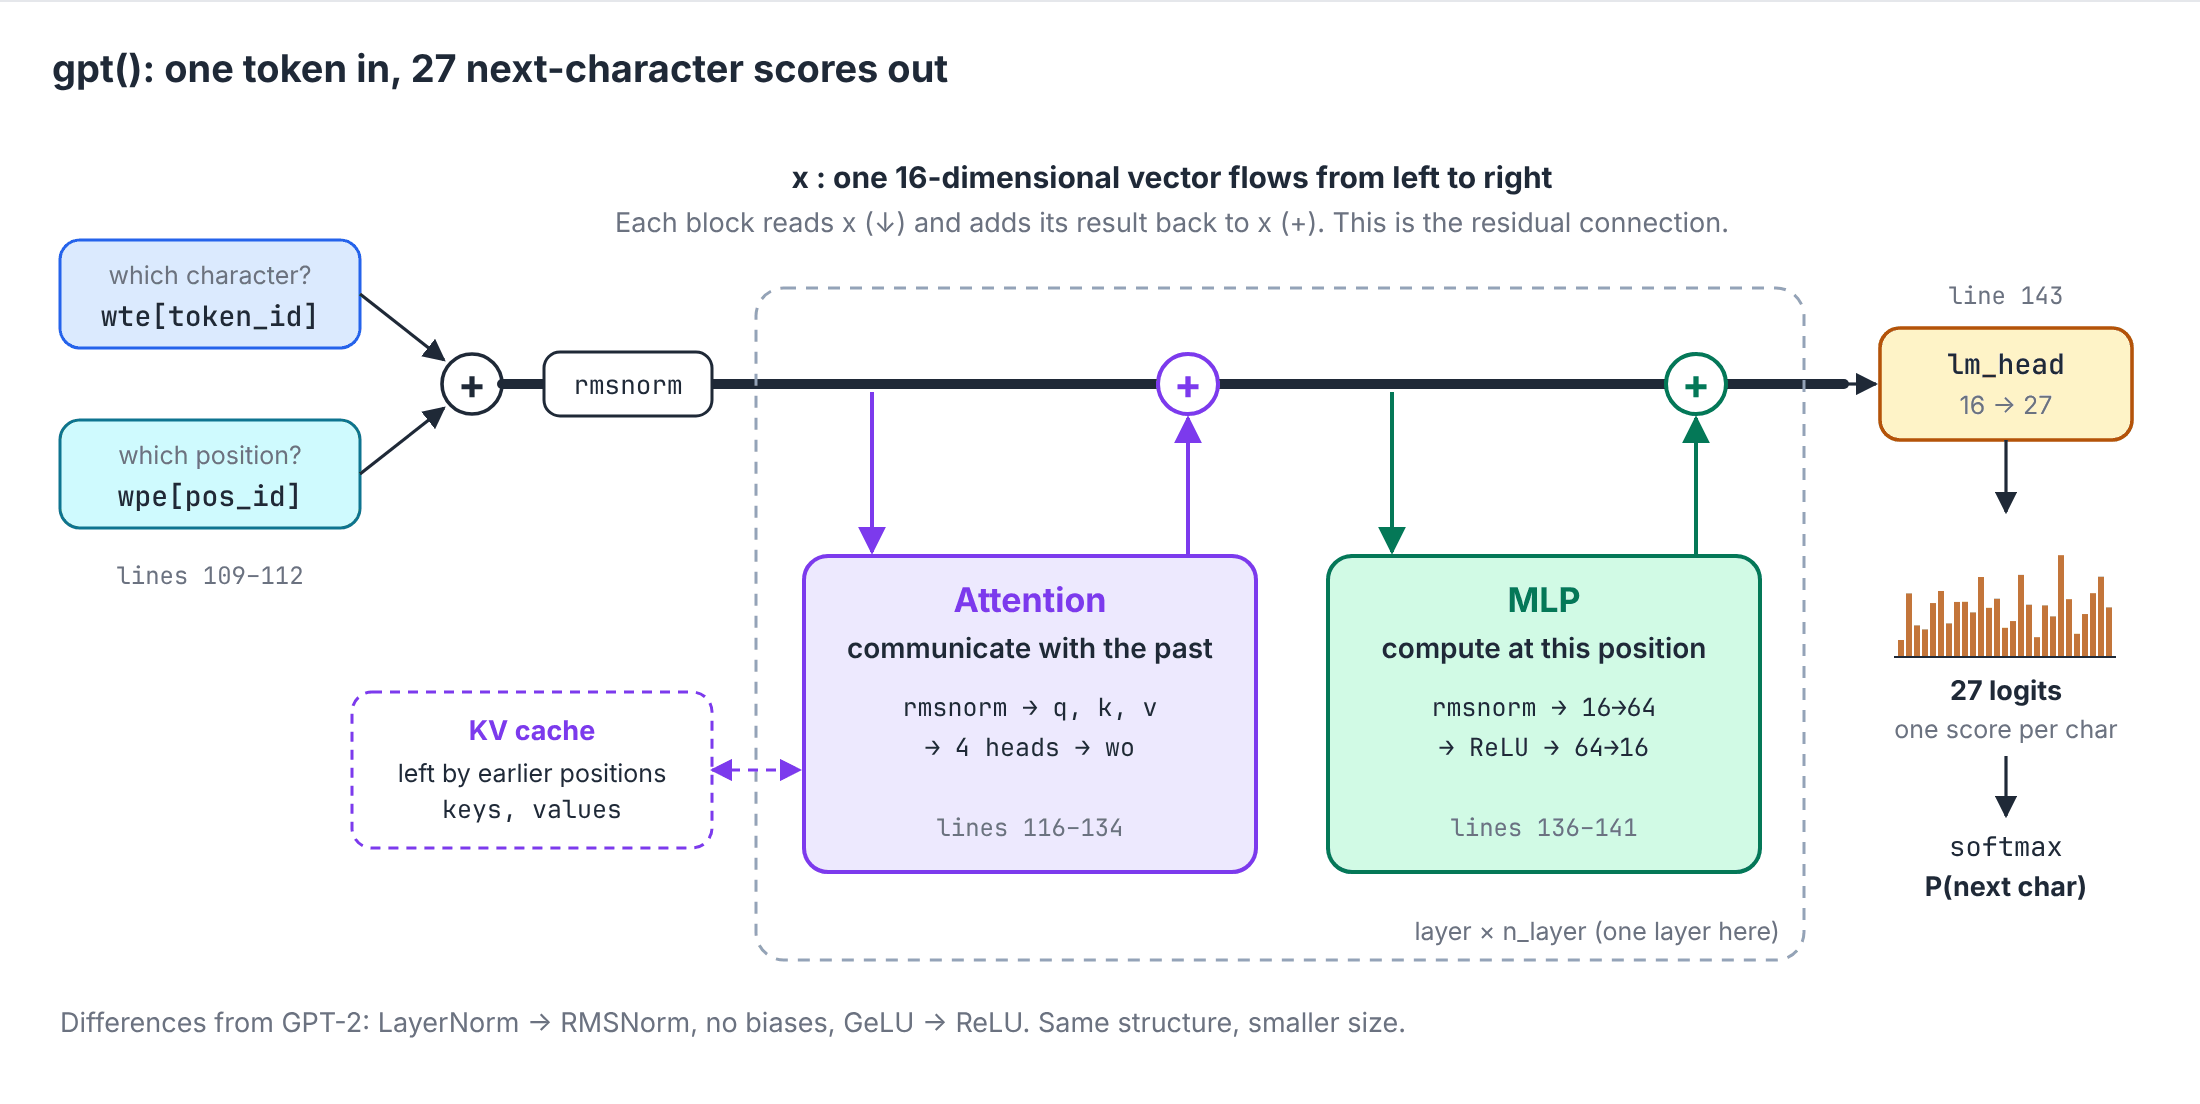

**① Embedding (lines 109–112)**: an integer cannot be used in the computation, so it is turned into a vector. "Which character" and "which position" are added.

```python
tok_emb = state_dict['wte'][token_id]            # take one row of the table
pos_emb = state_dict['wpe'][pos_id]
x = [t + p for t, p in zip(tok_emb, pos_emb)]
```

**② Attention (lines 116–134)**: the **only** place where a token looks at earlier tokens.

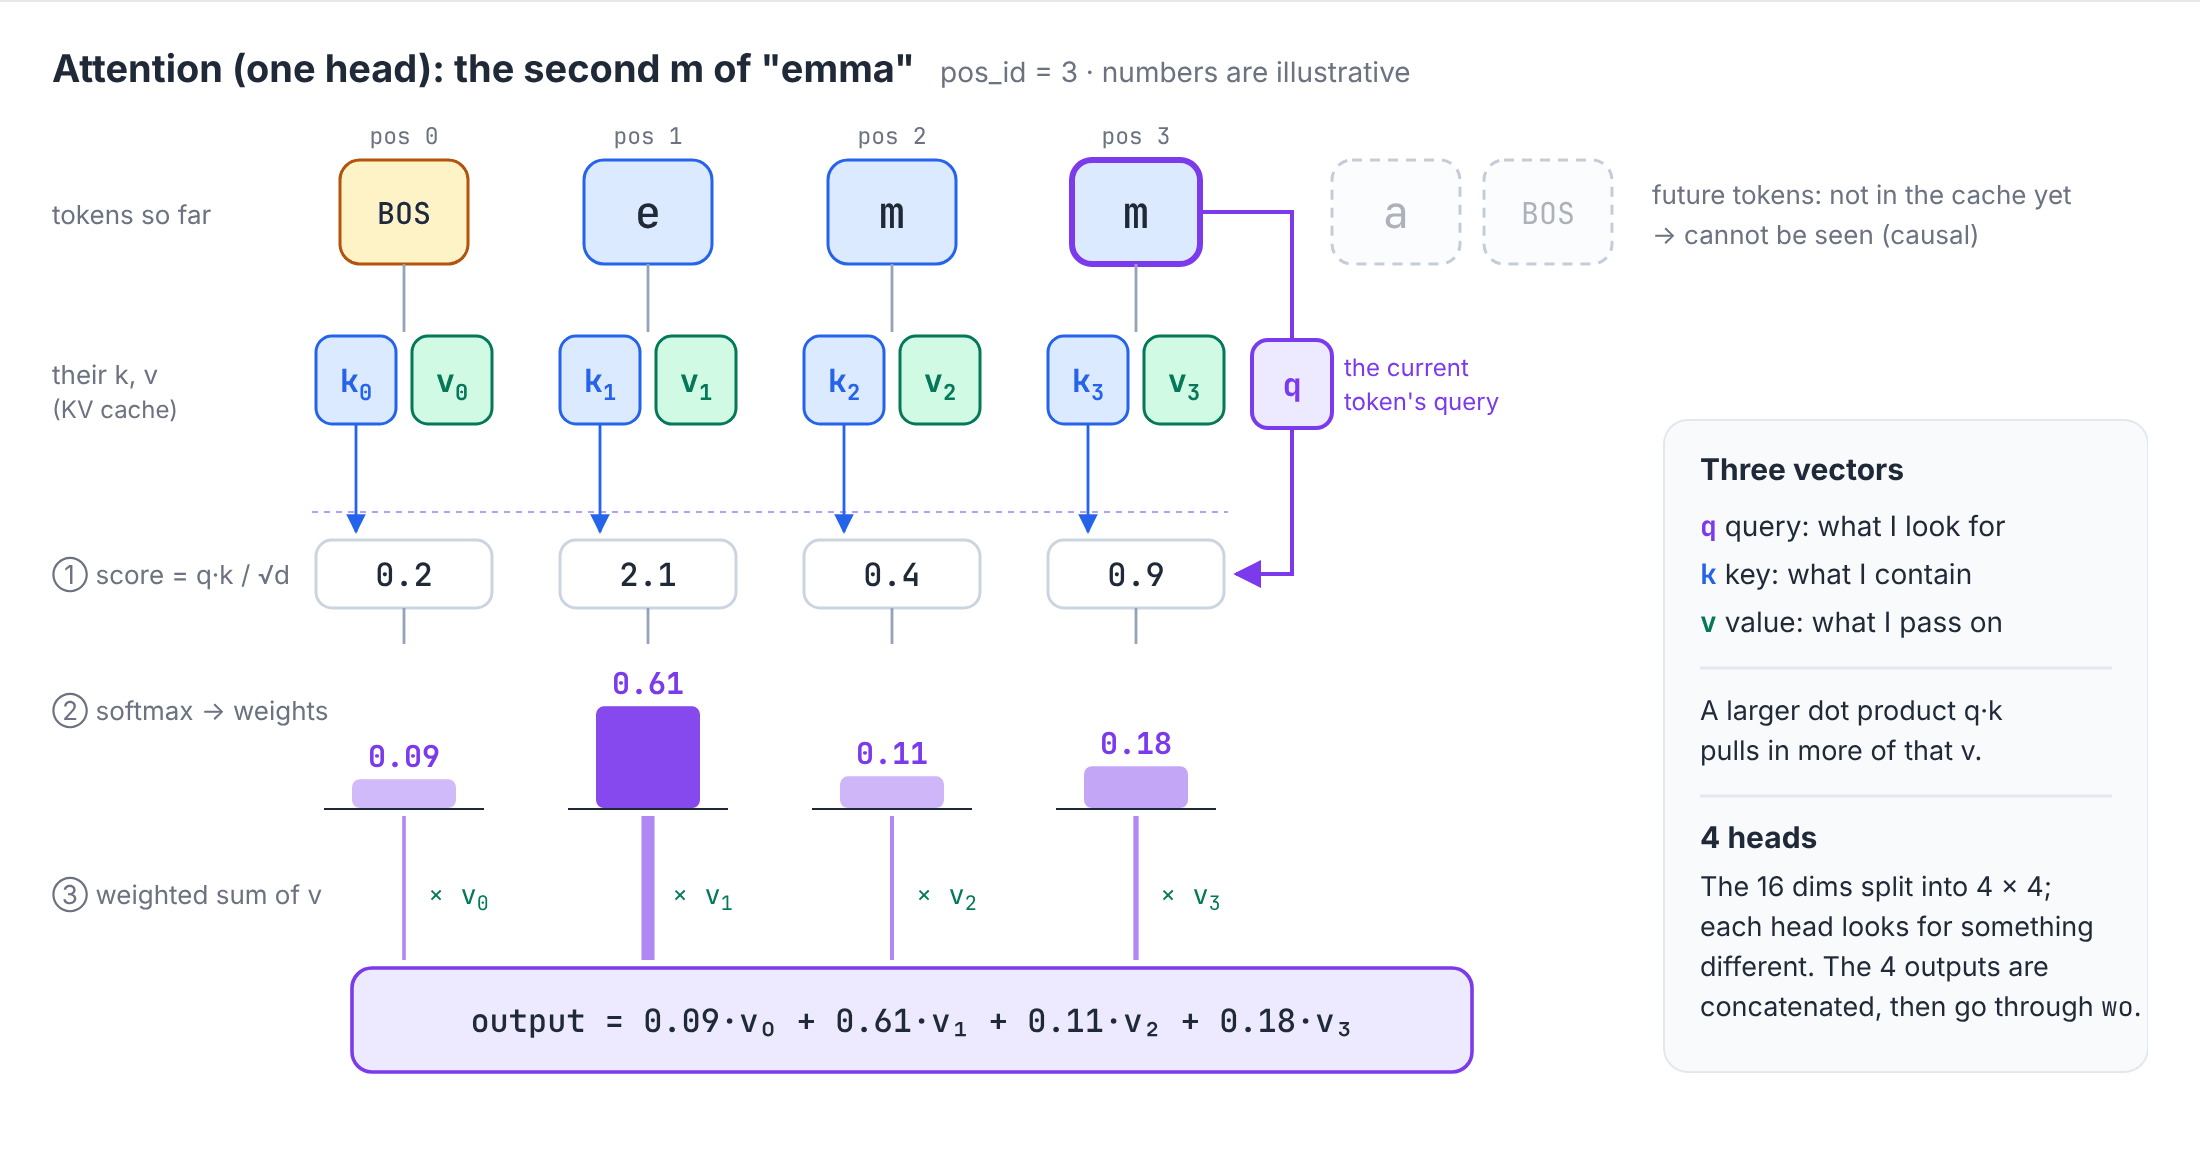

```python
q = linear(x, state_dict[f'layer{li}.attn_wq'])   # what I look for
k = linear(x, state_dict[f'layer{li}.attn_wk'])   # what I contain
v = linear(x, state_dict[f'layer{li}.attn_wv'])   # what I pass on
keys[li].append(k)                                # stored in the cache for later tokens
values[li].append(v)
...
# lines 129–131 in words (one head)
attn_logits  = [q·k_t / sqrt(head_dim) for t in tokens_so_far]   # ① scores
attn_weights = softmax(attn_logits)                              # ② weights
head_out     = Σ_t attn_weights[t] * v_t                         # ③ weighted sum
```

- The cache holds only the current and earlier tokens. No separate mask is needed to hide the future.
- softmax appears here again: the attention weights are also a Boltzmann distribution.

**③ MLP (lines 136–141)**: 16 → 64 dimensions → ReLU → 16 dimensions. It does not look at other tokens.

**④ Residual (lines 134, 141)**: the block output is **added** to its input. The original information is kept, and gradients reach the early layers.

**⑤ Output (line 143)**: `lm_head` maps 16 dimensions to 27 scores.

In short, a **Transformer alternates communication (Attention) and computation (MLP)**.

In [13]:
def gpt(token_id, pos_id, keys, values):
    tok_emb = state_dict['wte'][token_id] # token embedding
    pos_emb = state_dict['wpe'][pos_id] # position embedding
    x = [t + p for t, p in zip(tok_emb, pos_emb)] # joint token and position embedding
    x = rmsnorm(x) # note: not redundant due to backward pass via the residual connection

    for li in range(n_layer):
        # 1) Multi-head Attention block
        x_residual = x
        x = rmsnorm(x)
        q = linear(x, state_dict[f'layer{li}.attn_wq'])
        k = linear(x, state_dict[f'layer{li}.attn_wk'])
        v = linear(x, state_dict[f'layer{li}.attn_wv'])
        keys[li].append(k)
        values[li].append(v)
        x_attn = []
        for h in range(n_head):
            hs = h * head_dim
            q_h = q[hs:hs+head_dim]
            k_h = [ki[hs:hs+head_dim] for ki in keys[li]]
            v_h = [vi[hs:hs+head_dim] for vi in values[li]]
            attn_logits = [sum(q_h[j] * k_h[t][j] for j in range(head_dim)) / head_dim**0.5 for t in range(len(k_h))]
            attn_weights = softmax(attn_logits)
            head_out = [sum(attn_weights[t] * v_h[t][j] for t in range(len(v_h))) for j in range(head_dim)]
            x_attn.extend(head_out)
        x = linear(x_attn, state_dict[f'layer{li}.attn_wo'])
        x = [a + b for a, b in zip(x, x_residual)]
        # 2) MLP block
        x_residual = x
        x = rmsnorm(x)
        x = linear(x, state_dict[f'layer{li}.mlp_fc1'])
        x = [xi.relu() for xi in x]
        x = linear(x, state_dict[f'layer{li}.mlp_fc2'])
        x = [a + b for a, b in zip(x, x_residual)]

    logits = linear(x, state_dict['lm_head'])
    return logits

In [14]:
# [added] ask the untrained model: which character follows BOS?
keys, values = [[] for _ in range(n_layer)], [[] for _ in range(n_layer)]
logits = gpt(BOS, 0, keys, values)
probs = softmax(logits)
print("27 probabilities:", " ".join(f"{p.data:.3f}" for p in probs))
print(f"uniform guess: 1/27 = {1/27:.3f},  loss for that guess = ln 27 = {math.log(27):.3f}")

27 probabilities: 0.032 0.040 0.054 0.019 0.045 0.031 0.029 0.038 0.033 0.049 0.050 0.046 0.022 0.034 0.062 0.029 0.032 0.018 0.055 0.029 0.043 0.027 0.029 0.045 0.027 0.051 0.033
uniform guess: 1/27 = 0.037,  loss for that guess = ln 27 = 3.296


The parameters are random, so every character has nearly the same probability. The model knows nothing yet.

## §6 Training loop <small>(lines 146–184)</small>

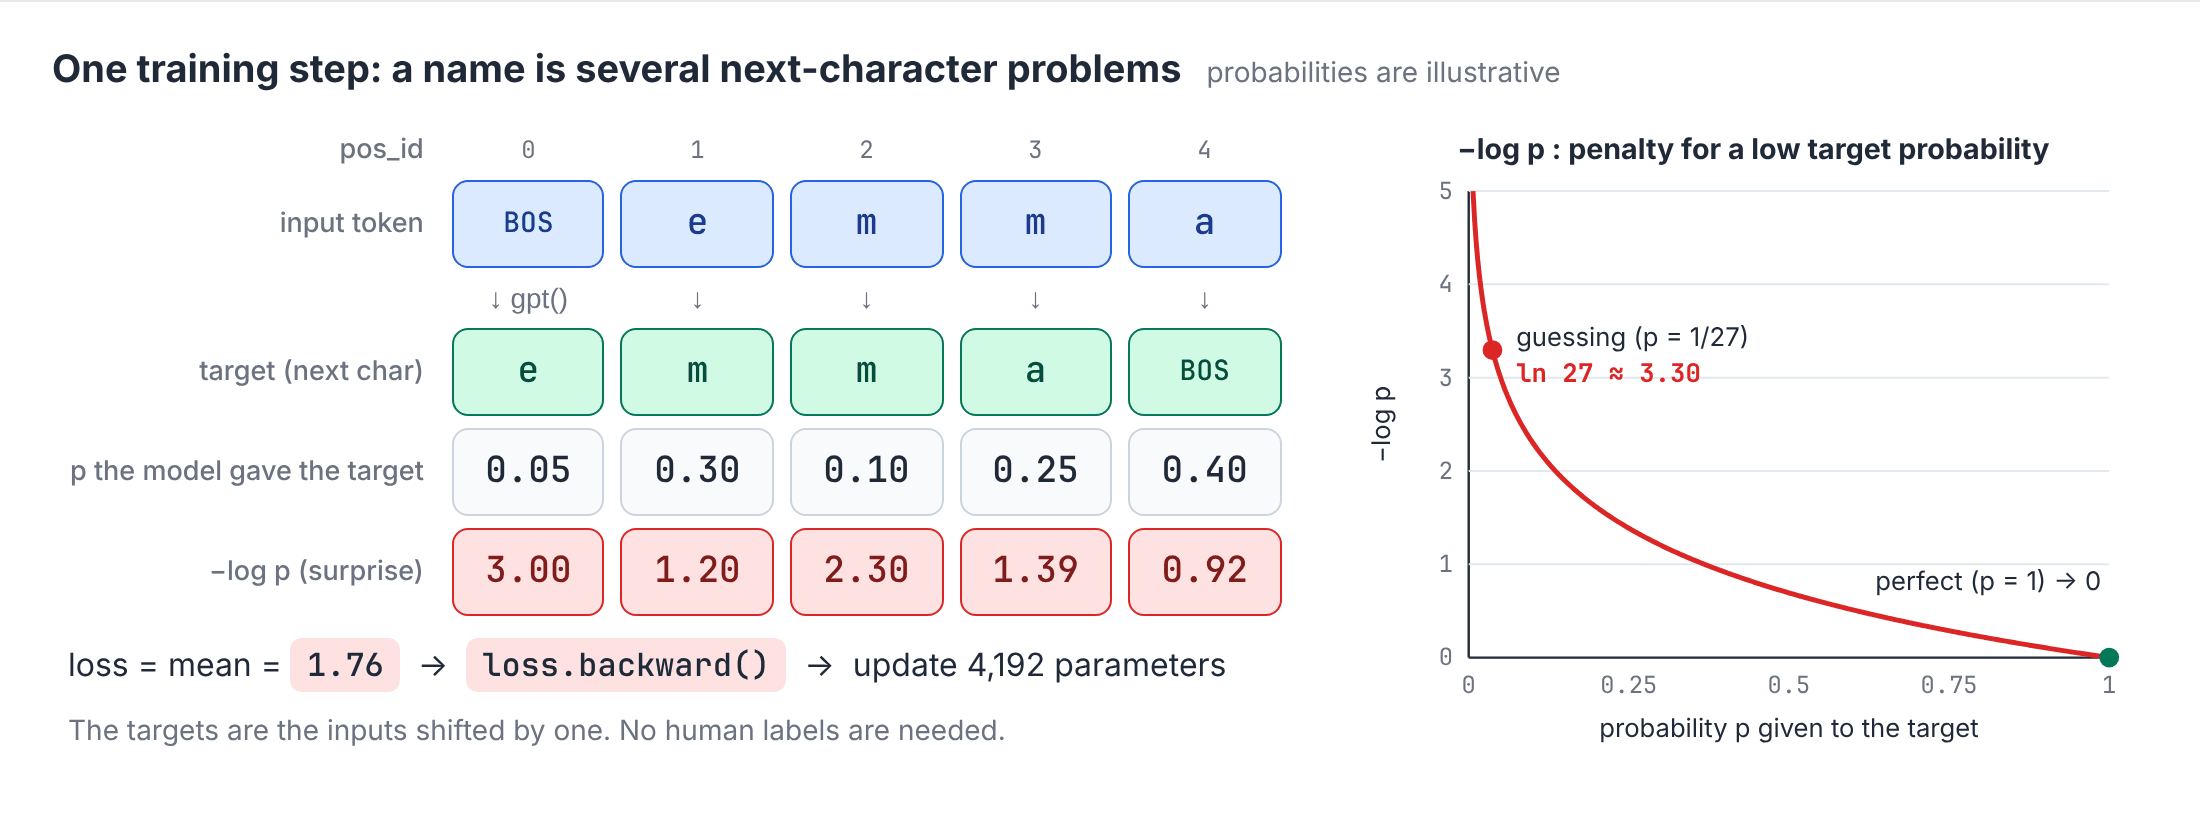

One step (lines 153–184):

1. Pick one name and convert it to tokens (lines 156–158).
2. **forward**: call `gpt()` at each position to get the next-character probabilities, and collect `-log p` of the target (lines 161–169).
3. **backward**: one line, `loss.backward()`, gives all 4,192 gradients (line 172).
4. **update**: Adam changes the parameters and the gradients are reset to 0 (lines 175–182).

**loss = cross-entropy = mean of $-\ln p(\text{target})$.** Before training it starts near $\ln 27 \approx 3.30$.

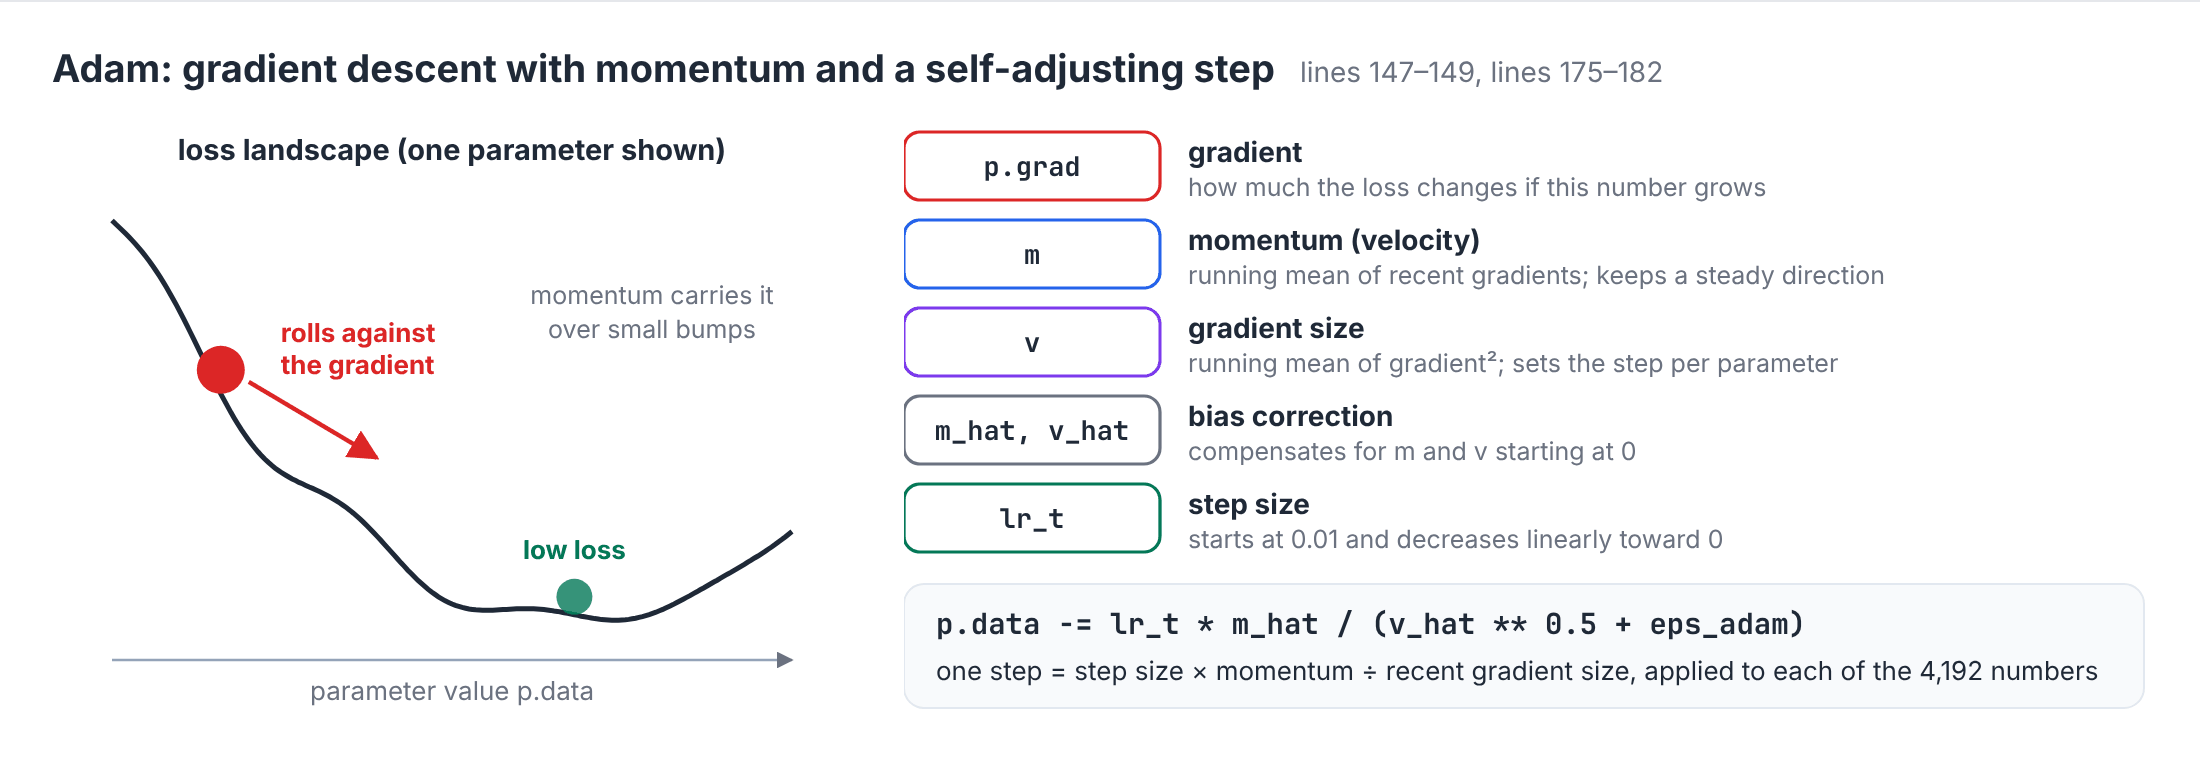

The simplest update is `p.data -= lr * p.grad` (gradient descent). Adam adds momentum (`m`) and a per-parameter step size (`v`).

In [15]:
# Let there be Adam, the blessed optimizer and its buffers
learning_rate, beta1, beta2, eps_adam = 0.01, 0.85, 0.99, 1e-8
m = [0.0] * len(params) # first moment buffer
v = [0.0] * len(params) # second moment buffer

The next cell is the training. **It takes 1 to 2 minutes.** Progress is printed on one line that is overwritten.

In [16]:
# Repeat in sequence
num_steps = 1000 # number of training steps
loss_history = [] # [added] record for the plot
for step in range(num_steps):

    # Take single document, tokenize it, surround it with BOS special token on both sides
    doc = docs[step % len(docs)]
    tokens = [BOS] + [uchars.index(ch) for ch in doc] + [BOS]
    n = min(block_size, len(tokens) - 1)

    # Forward the token sequence through the model, building up the computation graph all the way to the loss
    keys, values = [[] for _ in range(n_layer)], [[] for _ in range(n_layer)]
    losses = []
    for pos_id in range(n):
        token_id, target_id = tokens[pos_id], tokens[pos_id + 1]
        logits = gpt(token_id, pos_id, keys, values)
        probs = softmax(logits)
        loss_t = -probs[target_id].log()
        losses.append(loss_t)
    loss = (1 / n) * sum(losses) # final average loss over the document sequence. May yours be low.
    loss_history.append(loss.data) # [added]

    # Backward the loss, calculating the gradients with respect to all model parameters
    loss.backward()

    # Adam optimizer update: update the model parameters based on the corresponding gradients
    lr_t = learning_rate * (1 - step / num_steps) # linear learning rate decay
    for i, p in enumerate(params):
        m[i] = beta1 * m[i] + (1 - beta1) * p.grad
        v[i] = beta2 * v[i] + (1 - beta2) * p.grad ** 2
        m_hat = m[i] / (1 - beta1 ** (step + 1))
        v_hat = v[i] / (1 - beta2 ** (step + 1))
        p.data -= lr_t * m_hat / (v_hat ** 0.5 + eps_adam)
        p.grad = 0

    print(f"step {step+1:4d} / {num_steps:4d} | loss {loss.data:.4f}", end='\r')

step 1000 / 1000 | loss 2.6497

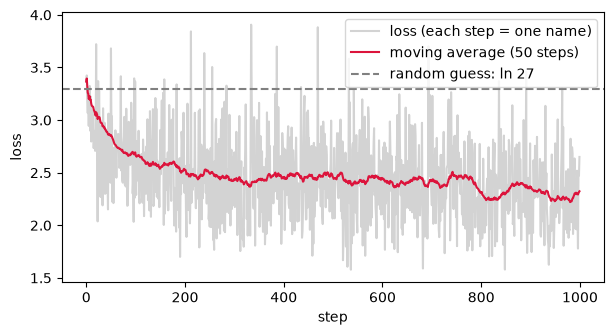

mean loss over the last 50 steps = 2.323


In [17]:
# [added] loss curve (needs matplotlib)
import matplotlib.pyplot as plt

window = 50
smooth = [sum(loss_history[max(0, i - window + 1):i + 1]) / (i + 1 - max(0, i - window + 1)) for i in range(len(loss_history))]
plt.figure(figsize=(7, 3.5))
plt.plot(loss_history, color="lightgray", label="loss (each step = one name)")
plt.plot(smooth, color="crimson", label=f"moving average ({window} steps)")
plt.axhline(math.log(vocab_size), color="gray", ls="--", label="random guess: ln 27")
plt.xlabel("step"); plt.ylabel("loss"); plt.legend(); plt.show()
print(f"mean loss over the last {window} steps = {smooth[-1]:.3f}")

The loss fluctuates because each step uses a different name, but its average falls from 3.3. The model is learning the statistics of names.

## §7 Inference <small>(lines 186–200)</small>

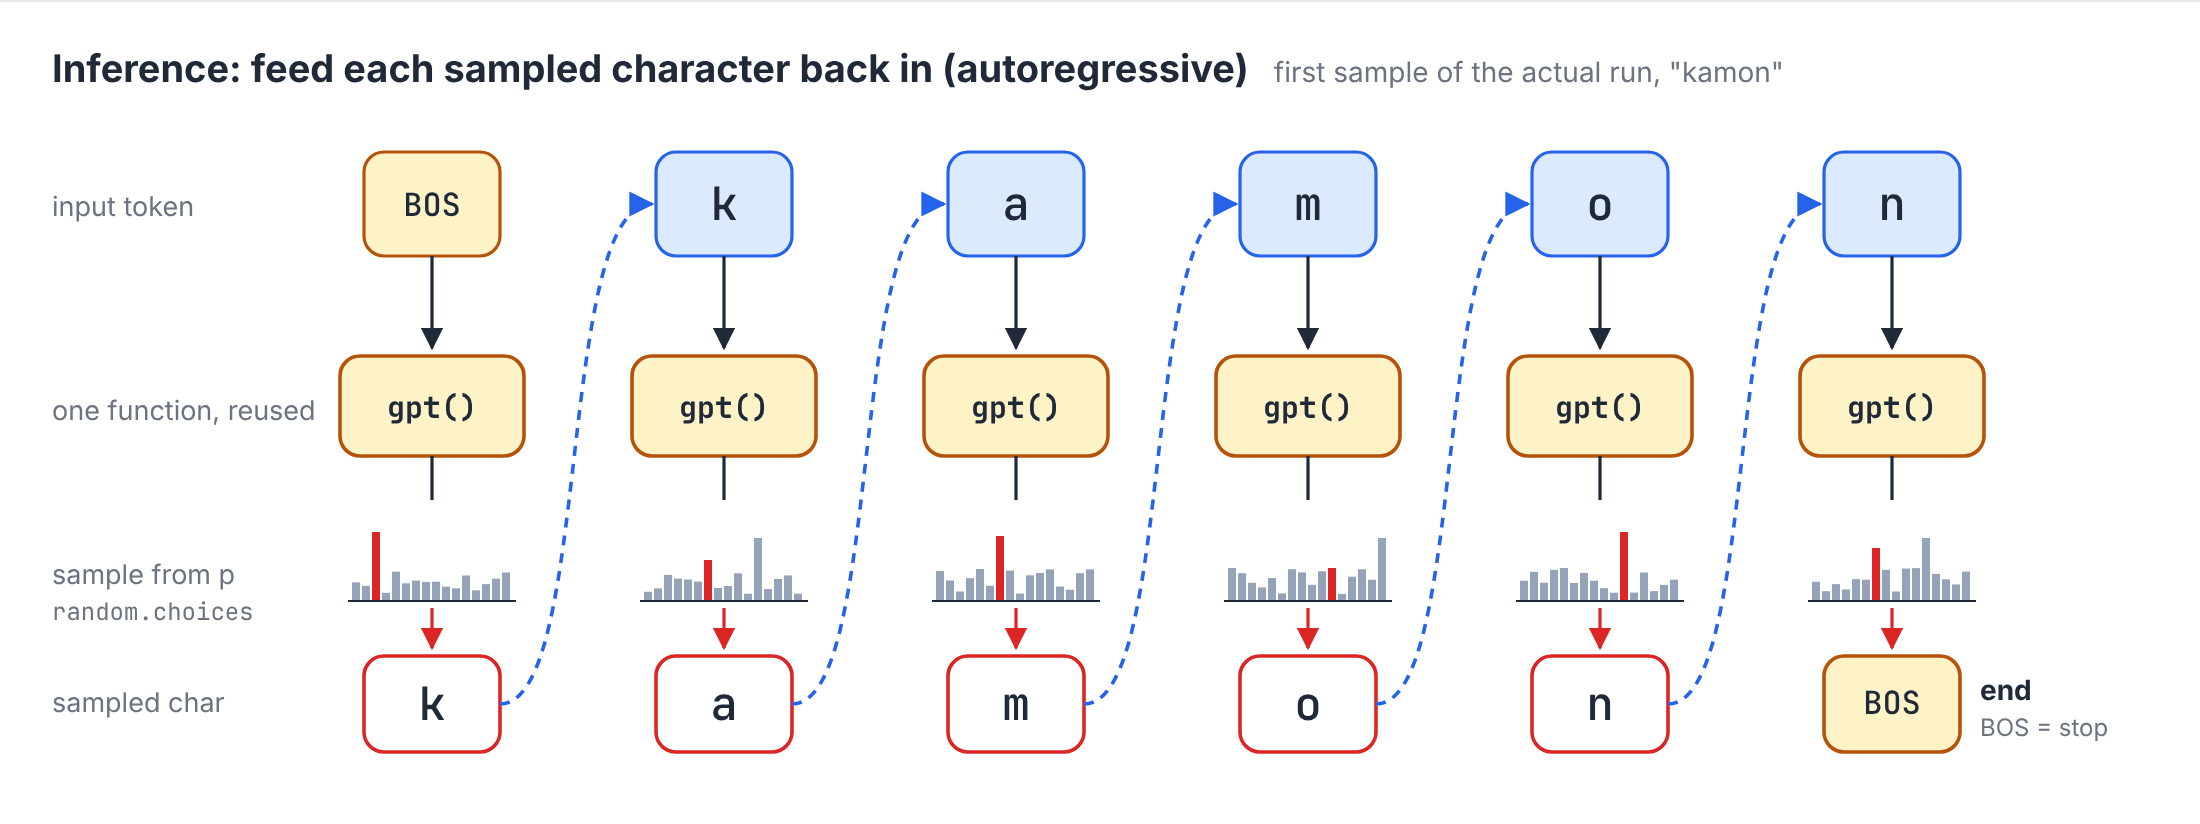

- Start from `BOS`, sample one character from the probabilities (`random.choices`), and feed it back in as the next input.
- When `BOS` is sampled, the name is finished.
- Line 195: `softmax([l / temperature for l in logits])`. The logits are divided by the temperature before sampling.

ChatGPT writes its answers with the same loop.

In [18]:
# Inference: may the model babble back to us
temperature = 0.5 # in (0, 1], control the "creativity" of generated text, low to high
print("\n--- inference (new, hallucinated names) ---")
for sample_idx in range(20):
    keys, values = [[] for _ in range(n_layer)], [[] for _ in range(n_layer)]
    token_id = BOS
    sample = []
    for pos_id in range(block_size):
        logits = gpt(token_id, pos_id, keys, values)
        probs = softmax([l / temperature for l in logits])
        token_id = random.choices(range(vocab_size), weights=[p.data for p in probs])[0]
        if token_id == BOS:
            break
        sample.append(uchars[token_id])
    print(f"sample {sample_idx+1:2d}: {''.join(sample)}")


--- inference (new, hallucinated names) ---
sample  1: kamon
sample  2: ann
sample  3: karai
sample  4: jaire
sample  5: vialan
sample  6: karia
sample  7: yeran
sample  8: anna
sample  9: areli
sample 10: kaina
sample 11: konna
sample 12: keylen
sample 13: liole
sample 14: alerin
sample 15: earan
sample 16: lenne
sample 17: kana
sample 18: lara
sample 19: alela
sample 20: anton


### Experiment 1: temperature

Check the Boltzmann picture of §5.1 on the trained model. The inference code is wrapped in a function so that only the temperature changes.

In [19]:
# [added] generate at several temperatures (lines 190–199 of the inference code, wrapped in a function)
def generate(temperature):
    keys, values = [[] for _ in range(n_layer)], [[] for _ in range(n_layer)]
    token_id = BOS
    sample = []
    for pos_id in range(block_size):
        logits = gpt(token_id, pos_id, keys, values)
        probs = softmax([l / temperature for l in logits])
        token_id = random.choices(range(vocab_size), weights=[p.data for p in probs])[0]
        if token_id == BOS:
            break
        sample.append(uchars[token_id])
    return ''.join(sample)

for T in [0.1, 0.5, 1.0, 2.0]:
    print(f"T = {T}:", ", ".join(generate(T) for _ in range(8)))

T = 0.1: anan, anan, anan, anan, alelen, anala, anan, anan
T = 0.5: adalan, darir, azaly, kigan, mialla, jarin, saria, stira
T = 1.0: sana, jaynann, jibyn, moree, amabem, irlil, enngyn, lacer
T = 2.0: urnlllata, wolenmptud, ikn, nol, sldina, raarnt, gcegiar, ranalk


At low temperature the most common pattern repeats. At high temperature the strings stop looking like names.

### Experiment 2: what did the model learn?

Compare the distribution of the first character with the data. Give the model only `BOS` and read the probabilities.

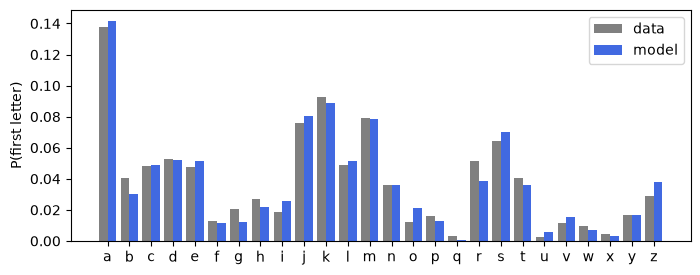

In [20]:
# [added] first-character distribution: data vs model
keys, values = [[] for _ in range(n_layer)], [[] for _ in range(n_layer)]
p_model = [p.data for p in softmax(gpt(BOS, 0, keys, values))][:BOS]
p_data = [sum(d[0] == ch for d in docs) / len(docs) for ch in uchars]

xs = range(len(uchars))
plt.figure(figsize=(8, 3))
plt.bar([x - 0.2 for x in xs], p_data, width=0.4, color="gray", label="data")
plt.bar([x + 0.2 for x in xs], p_model, width=0.4, color="royalblue", label="model")
plt.xticks(xs, uchars); plt.ylabel("P(first letter)"); plt.legend(); plt.show()

### Experiment 3: where does attention look?

Every time the softmax inside `gpt()` computes attention weights, the values are recorded and plotted per head.
Rows are the current token, columns are the tokens it attends to (the upper triangle is the future and stays empty).

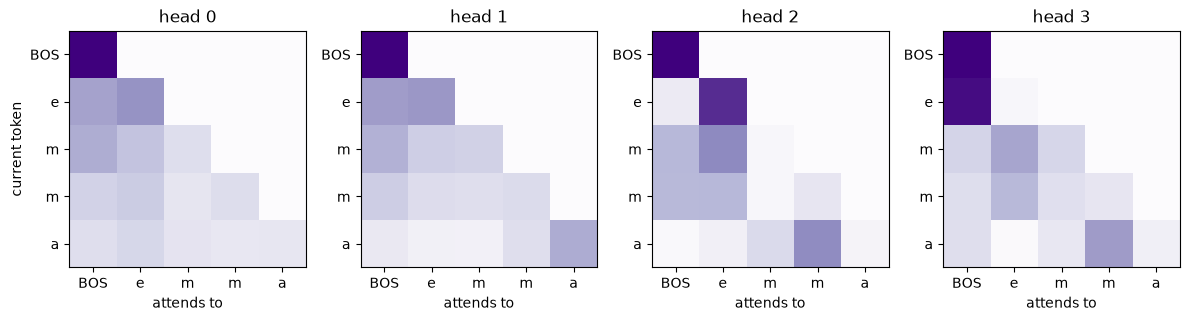

In [21]:
# [added] extract the attention weights of the trained model
def attention_map(name):
    global softmax
    record, original = [], softmax
    def spy(logits):                      # wrap softmax for a moment and record its output
        out = original(logits)
        record.append([p.data for p in out])
        return out
    softmax = spy
    try:
        tokens = [BOS] + [uchars.index(ch) for ch in name]
        keys, values = [[] for _ in range(n_layer)], [[] for _ in range(n_layer)]
        for pos_id, token_id in enumerate(tokens):
            gpt(token_id, pos_id, keys, values)
    finally:
        softmax = original                # restore
    return record                         # per position: (layer x head) lists of weights

name = "emma"
record = attention_map(name)
labels = ["BOS"] + list(name)
size = len(labels)
fig, axes = plt.subplots(1, n_head, figsize=(3 * n_head, 3.3), squeeze=False)
for h, ax in enumerate(axes[0]):          # heads of the first layer
    A = [record[pos * n_layer * n_head + h] + [0.0] * (size - pos - 1) for pos in range(size)]
    ax.imshow(A, cmap="Purples", vmin=0, vmax=1)
    ax.set_xticks(range(size)); ax.set_xticklabels(labels)
    ax.set_yticks(range(size)); ax.set_yticklabels(labels)
    ax.set_title(f"head {h}"); ax.set_xlabel("attends to")
axes[0][0].set_ylabel("current token")
plt.tight_layout(); plt.show()

Each head looks at different places. The model is small and trained for only 1,000 steps, so the patterns may not be sharp. Change `name` and compare.

## §8 How does a production GPT differ?

| | microgpt | Production LLM |
|---|---|---|
| Data | 32,000 names | trillions of tokens of internet text |
| Tokens | 27 characters | about 100,000 subword tokens (BPE) |
| Computation | pure Python, one scalar at a time | tensors on GPUs in parallel (same math) |
| Size | 4,192 parameters · 1 layer · 16 dimensions | hundreds of billions · 100+ layers · 10,000+ dimensions |
| Training | one name per step, 1,000 steps | millions of tokens per step, thousands of GPUs for months |
| After training | nothing | further training on conversations, reinforcement learning |

The skeleton of the algorithm is the same: predict the next token → loss → backward → update, then sample one token at a time.
A model stating something plausible but false (hallucination) is the same phenomenon as the name "kamon". The model knows which sequences are probable, not which are true.

## §9 Exercises

1. **Temperature**: try `T = 0.01` and `T = 5` in `generate(T)` and explain the results with the Boltzmann distribution.
2. **Extend autograd**: add a `tanh()` method to `Value` and verify it against a numerical derivative.
3. **Initial loss**: why is the loss near $\ln 27$ before training? Where would it start if `vocab_size` were 100?
4. **Longer and larger**: change `num_steps`, `n_embd` and `n_layer`, train again, and compare the loss curves and the generated names. (The run time grows accordingly.)
5. **Without Adam**: replace line 181 with `p.data -= lr_t * p.grad`. How does the loss curve change?
6. **Other data**: replace `input.txt` with another list (city names, English words, romanized Korean names) and run again from §1. No code change is needed.

After changing a value in §4 or §6, run again from §4 so that the parameters are created anew.

## References

**Original**
- Karpathy's blog post: <https://karpathy.github.io/2026/02/12/microgpt/>
- Code (gist): <https://gist.github.com/karpathy/8627fe009c40f57531cb18360106ce95> · single page: <https://karpathy.ai/microgpt.html>
- Step-by-step build-up (bigram → MLP → autograd → attention → Adam, in the gist revisions): <https://gist.github.com/karpathy/561ac2de12a47cc06a23691e1be9543a>
- The author's Colab: <https://colab.research.google.com/drive/1vyN5zo6rqUp_dYNbT4Yrco66zuWCZKoN>

**Visual explanations of microgpt**
- MicroGPT Visualized: <https://microgpt.jtauber.com/> (each step split into substeps with diagrams and animations)
- MicroGPT explained interactively: <https://growingswe.com/blog/microgpt> (step through the code and watch intermediate values)
- ko-microgpt: <https://github.com/woduq1414/ko-microgpt> · demo <https://ko-microgpt.vercel.app> (Korean-name version with a visualization web app)

**Transformer visualizations**
- Transformer Explainer: <https://poloclub.github.io/transformer-explainer/> (runs GPT-2 in the browser, with a temperature slider)
- LLM Visualization: <https://bbycroft.net/llm> (every matrix operation of a small GPT in 3D)
- 3Blue1Brown videos: [Transformers, the tech behind LLMs](https://www.youtube.com/watch?v=wjZofJX0v4M) · [Attention in transformers, step-by-step](https://www.youtube.com/watch?v=eMlx5fFNoYc) · text version <https://www.3blue1brown.com/lessons/gpt>
- The Illustrated Transformer: <https://jalammar.github.io/illustrated-transformer/> · The Illustrated GPT-2: <https://jalammar.github.io/illustrated-gpt2/>
- Financial Times, "Generative AI exists because of the transformer": <https://ig.ft.com/generative-ai/>

**Going deeper**
- Karpathy videos: [micrograd, autograd from scratch](https://www.youtube.com/watch?v=VMj-3S1tku0) · [Let's build GPT](https://www.youtube.com/watch?v=kCc8FmEb1nY)
- Paper: Vaswani et al., "Attention Is All You Need" (2017), <https://arxiv.org/abs/1706.03762>